# DataCo Supply Chain Analytics

**The question:** where is this supply chain losing time and money, and what should order demand look like over the next six months?

**The data:** DataCo Smart Supply Chain dataset (Kaggle / Mendeley Data), 180,519 order lines from 1 Jan 2015 to 31 Jan 2018. The raw file isn't in this repo; `data/README.md` explains where to download it.

**Tools:** Python (pandas, matplotlib, statsmodels) for the analysis, with the dashboard built separately in Power BI.

### The short version

- Lateness is driven by **shipping mode, not geography**: 38% to 95% late by mode, versus 54.4% to 55.2% by market.
- **First Class** is promised in 1 day but takes 2. **Second Class** is promised in 2 days but takes about 4, the same as Standard.
- **18.7% of order lines lose money**, and those losses wipe out about half the profit earned on the profitable lines. They're spread evenly, not concentrated in one segment.
- Order volume is steady and seasonal, and a same-month-last-year baseline forecasts it to within about 1%.
- The data changes shape in **October 2017** (one line per order from then on), so I kept the forecast to the period before it.
- Several fields look rule-generated, so the findings describe this dataset rather than real-world behaviour (see the limitations at the end).

### Contents

1. Setup
2. Data quality
3. Exploratory analysis
4. Delivery performance
5. Profitability
6. Demand and forecast
7. Findings, recommendations and limitations
8. Exports for Power BI

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

In [2]:
# Colours and chart style, kept in one place so every chart matches
BLUE, RED, GREY = "#2E75B6", "#C0504D", "#7F7F7F"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#444444", "xtick.color": "#444444", "ytick.color": "#444444",
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def pretty(table, **formats):
    """Return a copy of `table` with the named columns formatted for display (percentages, thousands, etc.)."""
    out = table.copy()
    for col, fmt in formats.items():
        out[col] = out[col].map(fmt.format)
    return out

In [3]:
# Works whether the notebook sits in the project root or in a notebooks/ folder
CANDIDATES = [Path("data/DataCoSupplyChainDataset.csv"), Path("../data/DataCoSupplyChainDataset.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Put DataCoSupplyChainDataset.csv in the data/ folder (see data/README.md).")

OUTPUT_DIR = DATA_PATH.parent.parent / "output"
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Reading {DATA_PATH}; results will be saved to {OUTPUT_DIR}")

Reading ..\data\DataCoSupplyChainDataset.csv; results will be saved to ..\output


## 2. Data quality

First job: load the data, remove anything personal, and check it's fit to analyse.

In [4]:
# The file isn't UTF-8, so it needs latin-1
raw = pd.read_csv(DATA_PATH, encoding="latin-1")
raw.columns = [c.strip() for c in raw.columns]
print(f"Raw file: {raw.shape[0]:,} rows x {raw.shape[1]} columns")

Raw file: 180,519 rows x 53 columns


In [ ]:
# Remove personal details (and the product image link) before doing anything else - refer column names and description from description csv
PII_COLUMNS = ["Customer Email", "Customer Password", "Customer Fname", "Customer Lname",
               "Customer Street", "Product Image"]
removed = [c for c in PII_COLUMNS if c in raw.columns]
df = raw.drop(columns=removed)
print(f"Removed {len(removed)} columns: {', '.join(removed)}")

Removed 6 columns: Customer Email, Customer Password, Customer Fname, Customer Lname, Customer Street, Product Image


In [6]:
# Parse the two date columns
DATE, SHIP = "order date (DateOrders)", "shipping date (DateOrders)"
df[DATE] = pd.to_datetime(df[DATE], errors="coerce")
df[SHIP] = pd.to_datetime(df[SHIP], errors="coerce")

In [7]:
# Basic integrity checks
checks = {
    "Order lines": f"{len(df):,}",
    "Distinct orders": f"{df['Order Id'].nunique():,}",
    "Date range": f"{df[DATE].min():%d %b %Y} to {df[DATE].max():%d %b %Y}",
    "Duplicate rows": int(df.duplicated().sum()),
    "Unparseable order dates": int(df[DATE].isna().sum()),
    "Shipped before ordered": int((df[SHIP] < df[DATE]).sum()),
}
pd.Series(checks, name="Result").to_frame()

,Result
Order lines,"180,519"
Distinct orders,"65,752"
Date range,01 Jan 2015 to 31 Jan 2018
Duplicate rows,0
Unparseable order dates,0
Shipped before ordered,0


In [8]:
# Which columns have missing values?
missing = df.isna().mean().mul(100).round(2)
missing[missing > 0].sort_values(ascending=False).to_frame("% missing")

,% missing
Product Description,100.00
Order Zipcode,86.24


In [9]:
# Drop the two columns that are (almost) empty
EMPTY_COLUMNS = ["Product Description", "Order Zipcode"]
df = df.drop(columns=EMPTY_COLUMNS, errors="ignore")
print(f"Working dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")

Working dataset: 180,519 rows x 45 columns


**What I found**

- The data covers **180,519 order lines across 65,752 distinct orders**, from 1 Jan 2015 to 31 Jan 2018.
- The basics are clean: no duplicate rows, no unparseable order dates and no orders shipped before they were placed.
- Two columns are empty or nearly so: `Product Description` (100% missing) and `Order Zipcode` (86.2% missing). I dropped both and use order region, country and state for geography instead.
- I removed customer names, email, password, street and the product image link up front, since the analysis doesn't need them.

## 3. Exploratory analysis

Before answering the business questions, I wanted a feel for what a typical order line looks like and whether anything in the data looks odd.

### 3.1 Headline numbers

In [10]:
# Helper columns used throughout the notebook
df["late"] = (df["Delivery Status"] == "Late delivery").astype(int)            # 1 = arrived late
df["delay_days"] = df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
df["loss"] = (df["Order Profit Per Order"] < 0).astype(int)                      # 1 = line lost money
df["loss_amount"] = df["Order Profit Per Order"].clip(upper=0)                   # negative profit only

total_sales, net_profit = df["Sales"].sum(), df["Order Profit Per Order"].sum()
headline = {
    "Order lines": f"{len(df):,}",
    "Distinct orders": f"{df['Order Id'].nunique():,}",
    "Total sales": f"{total_sales:,.0f}",
    "Net profit": f"{net_profit:,.0f}",
    "Profit margin": f"{net_profit / total_sales:.1%}",
    "Late delivery rate": f"{df['late'].mean():.1%}",
    "Loss-making lines": f"{df['loss'].mean():.1%}",
}
pd.Series(headline, name="Value").to_frame()

,Value
Order lines,"180,519"
Distinct orders,"65,752"
Total sales,"36,784,735"
Net profit,"3,966,903"
Profit margin,10.8%
Late delivery rate,54.8%
Loss-making lines,18.7%


### 3.2 Distributions

In [11]:
# Summary statistics for the main numeric fields
num_cols = ["Sales", "Order Profit Per Order", "Order Item Discount Rate", "Order Item Quantity",
            "Product Price", "Days for shipping (real)", "Days for shipment (scheduled)"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Sales,180519.0,203.77,132.27,9.99,119.98,199.92,299.95,1999.99
Order Profit Per Order,180519.0,21.97,104.43,-4274.98,7.00,31.52,64.80,911.80
Order Item Discount Rate,180519.0,0.10,0.07,0.00,0.04,0.10,0.16,0.25
Order Item Quantity,180519.0,2.13,1.45,1.00,1.00,1.00,3.00,5.00
Product Price,180519.0,141.23,139.73,9.99,50.00,59.99,199.99,1999.99
Days for shipping (real),180519.0,3.50,1.62,0.00,2.00,3.00,5.00,6.00
Days for shipment (scheduled),180519.0,2.93,1.37,0.00,2.00,4.00,4.00,4.00


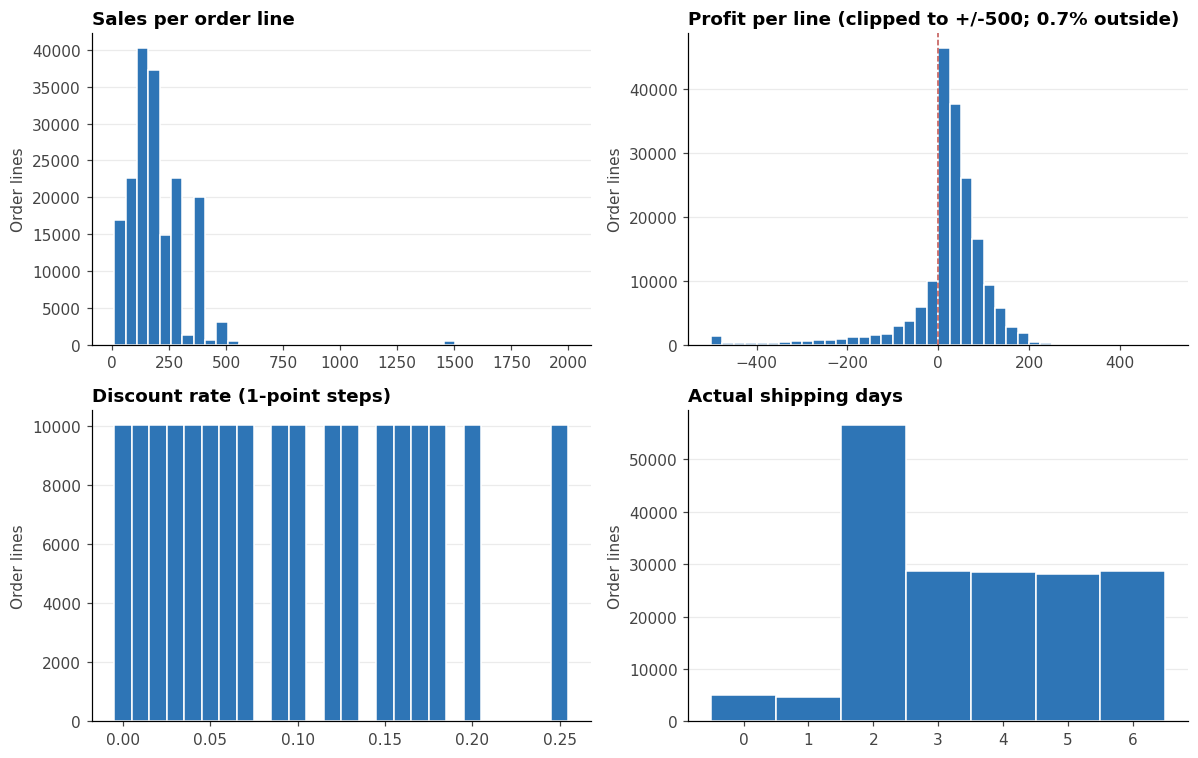

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].hist(df["Sales"], bins=40, color=BLUE, edgecolor="white")
axes[0, 0].set_title("Sales per order line")

profit = df["Order Profit Per Order"]
axes[0, 1].hist(profit.clip(-500, 500), bins=np.linspace(-500, 500, 41), color=BLUE, edgecolor="white")
axes[0, 1].axvline(0, color=RED, linestyle="--", linewidth=1)
axes[0, 1].set_title(f"Profit per line (clipped to +/-500; {(profit.abs() > 500).mean():.1%} outside)")

axes[1, 0].hist(df["Order Item Discount Rate"], bins=np.arange(-0.005, 0.26, 0.01), color=BLUE, edgecolor="white")
axes[1, 0].set_title("Discount rate (1-point steps)")

axes[1, 1].hist(df["Days for shipping (real)"], bins=np.arange(-0.5, 7.5, 1), color=BLUE, edgecolor="white")
axes[1, 1].set_title("Actual shipping days")

for ax in axes.ravel():
    ax.set_ylabel("Order lines")
plt.tight_layout(); plt.show()

**What I found**

- Sales per line are right-skewed: the median is about 200 (mean 204), with a small cluster of high-ticket items up to 2,000.
- Profit per line sits just above zero with a long tail of losses. The mean (22) is pulled below the median (31.5) by that tail, though only 0.7% of lines fall outside +/-500.
- Discounts come in whole-percentage steps from 0% to 25%.
- Actual shipping takes 0 to 6 days (3.5 on average), and the biggest single group is 2 days.

### 3.3 What the orders look like

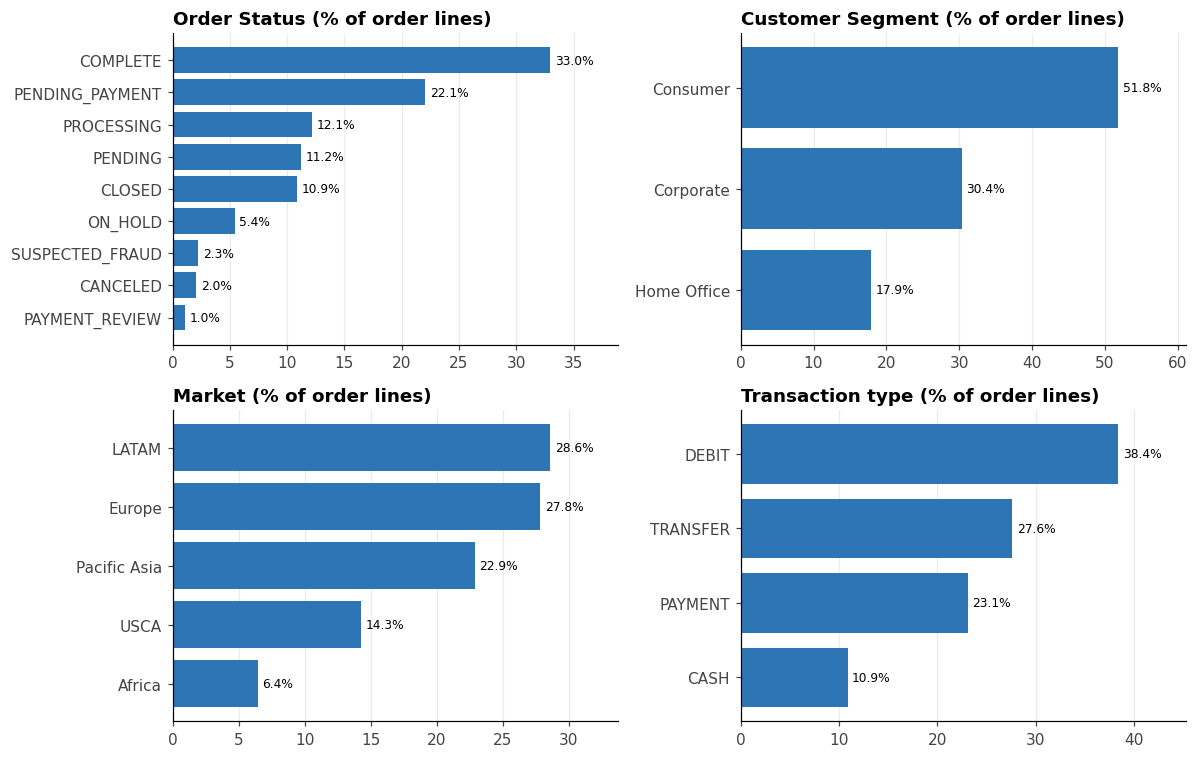

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["Order Status", "Customer Segment", "Market", "Type"]):
    share = df[col].value_counts(normalize=True).mul(100).sort_values()
    ax.barh(share.index, share.values, color=BLUE)
    ax.set_title(f"{'Transaction type' if col == 'Type' else col} (% of order lines)")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
    ax.set_xlim(0, share.max() * 1.18)
    ax.grid(axis="y", visible=False); ax.grid(axis="x")
plt.tight_layout(); plt.show()

**What I found**

- Only about **44% of lines are complete or closed** (33.0% and 10.9%). Another 22.1% are pending payment, so the sales totals include a lot of orders that aren't finalised.
- Cancelled (2.0%) and suspected-fraud (2.3%) orders make up about 4.3% of lines. They're still in the totals, so I'd filter them out of any revenue reporting.
- Consumers are 51.8% of lines, Corporate 30.4% and Home Office 17.9%.
- LATAM (28.6%) and Europe (27.8%) are the biggest markets, and Africa is the smallest at 6.4%.
- Debit is the most common transaction type (38.4%), then transfer (27.6%), payment (23.1%) and cash (10.9%).

### 3.4 Products

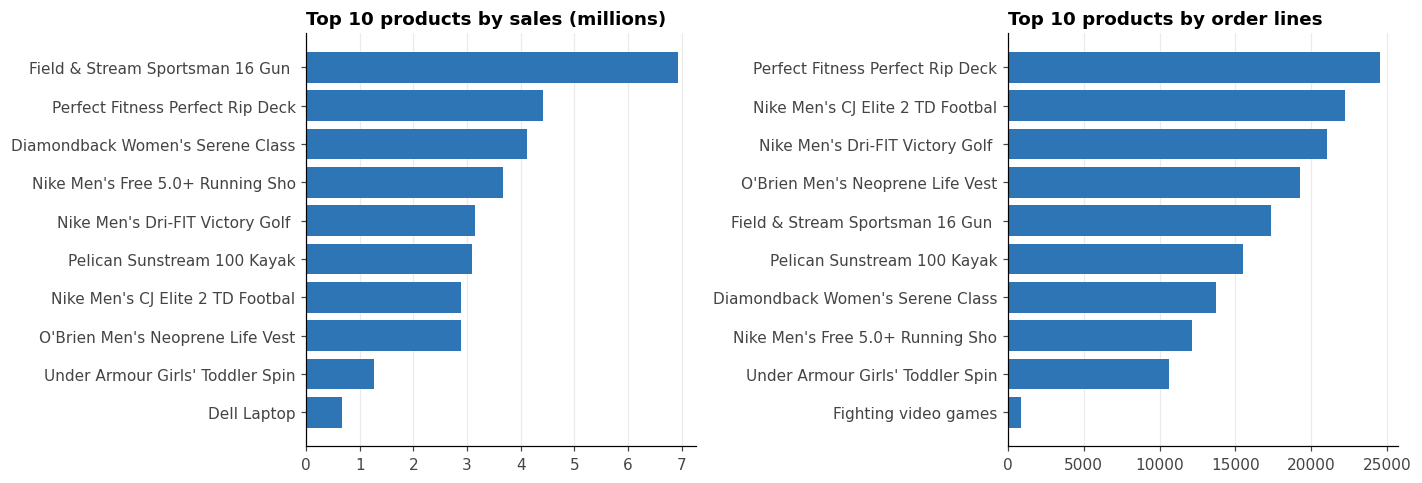

The top 10 products make up 87.1% of order lines, out of 118 products in total


In [14]:
top_sales = df.groupby("Product Name")["Sales"].sum().nlargest(10).sort_values()
top_lines = df["Product Name"].value_counts().head(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(top_sales.index.str[:32], top_sales.values / 1e6, color=BLUE)
axes[0].set_title("Top 10 products by sales (millions)")
axes[1].barh(top_lines.index.str[:32], top_lines.values, color=BLUE)
axes[1].set_title("Top 10 products by order lines")
for ax in axes:
    ax.grid(axis="y", visible=False); ax.grid(axis="x")
plt.tight_layout(); plt.show()

top10_share = df["Product Name"].value_counts(normalize=True).head(10).sum()
print(f"The top 10 products make up {top10_share:.1%} of order lines, out of {df['Product Name'].nunique()} products in total")

**What I found**

- The catalogue is **very concentrated**: the top 10 products account for 87.1% of order lines, out of 118 products.
- The Field & Stream gun safe leads on sales, while the Perfect Fitness Perfect Rip Deck leads on order lines (24,515).
- Several of the biggest categories are essentially a single product each, so category and product results end up looking alike.

### 3.5 Seasonality

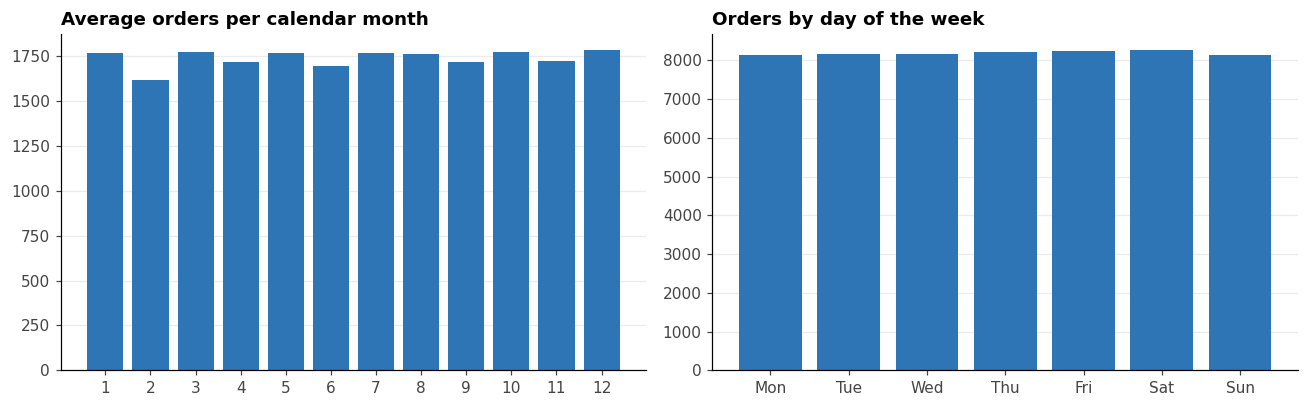

In [15]:
# Stable period only (the data changes shape from Oct 2017, see section 6)
stable_lines = df[df[DATE] < "2017-10-01"]

# Average each calendar month over the years that actually exist for it
orders_per_month = stable_lines.groupby(stable_lines[DATE].dt.to_period("M"))["Order Id"].nunique()
by_month = orders_per_month.groupby(orders_per_month.index.month).mean()

by_weekday = stable_lines.groupby(stable_lines[DATE].dt.dayofweek)["Order Id"].nunique()
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(by_month.index, by_month.values, color=BLUE)
axes[0].set_xticks(range(1, 13)); axes[0].set_title("Average orders per calendar month")
axes[1].bar(by_weekday.index, by_weekday.values, color=BLUE)
axes[1].set_title("Orders by day of the week")
plt.tight_layout(); plt.show()

**What I found**

- Orders are steady through the year, with February the quietest month (1,614 orders in Feb 2017).
- There's no weekday pattern: orders are spread evenly across all seven days.

### 3.6 Relationships between fields

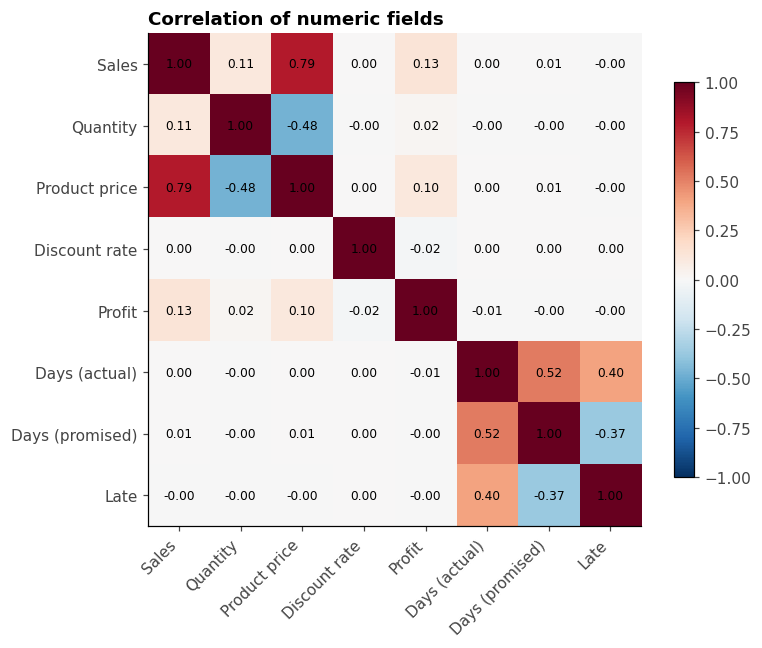

In [16]:
labels = {"Sales": "Sales", "Order Item Quantity": "Quantity", "Product Price": "Product price",
          "Order Item Discount Rate": "Discount rate", "Order Profit Per Order": "Profit",
          "Days for shipping (real)": "Days (actual)", "Days for shipment (scheduled)": "Days (promised)",
          "late": "Late"}
corr = df[list(labels)].corr().rename(index=labels, columns=labels)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); ax.set_title("Correlation of numeric fields")
fig.colorbar(im, shrink=0.8); plt.tight_layout(); plt.show()

**What I found**

- Sales track product price closely (0.79), and quantity falls as price rises (-0.48), so people buy fewer of the expensive items.
- Lateness rises with actual shipping days (0.40) and falls as the promised days get longer (-0.37). Shorter promises are missed more often.
- Profit is only weakly related to sales (0.13) and price (0.10), and essentially unrelated to discount (-0.02) or shipping days. There's no cost field in the data, so these columns can't explain why profit varies.

### 3.7 Two things I double-checked

In [17]:
# 1. How much do the extreme losses matter?
extreme = df[df["Order Profit Per Order"] < -1000]
extreme_total = extreme["Order Profit Per Order"].sum()
print(f"{len(extreme)} lines lose more than 1,000 each: {extreme_total:,.0f} in total "
      f"({extreme_total / df['loss_amount'].sum():.1%} of all losses)")
extreme["Product Name"].value_counts().head(5).to_frame("lines")

76 lines lose more than 1,000 each: -112,577 in total (2.9% of all losses)


,lines
Product Name,
Dell Laptop,29
Field & Stream Sportsman 16 Gun Fire Safe,19
Nike Men's Free 5.0+ Running Shoe,15
Web Camera,4
Lawn mower,3


In [18]:
# 2. How are discounts distributed?
levels = df["Order Item Discount Rate"].round(2).value_counts().sort_index()
print(f"{len(levels)} distinct discount levels, each used on {levels.min():,} to {levels.max():,} order lines")
levels.to_frame("order lines").T

18 distinct discount levels, each used on 10,028 to 10,029 order lines


Order Item Discount Rate,0.00,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.09,0.10,0.12,0.13,0.15,0.16,0.17,0.18,0.20,0.25
order lines,10028,10028,10028,10029,10029,10029,10029,10029,10029,10029,10029,10029,10029,10029,10029,10029,10029,10029


**What I found**

- Extreme losses are rare. **76 lines lose more than 1,000 each**, together 112,577 or just 2.9% of all losses. Most are the Dell Laptop (29), the Field & Stream gun safe (19) and the Nike Free 5.0+ (15).
- Discounts take only **18 distinct values** (0% to 25%), and each one is used on almost exactly the same number of lines (10,028 or 10,029). Real customers don't behave this evenly, so I'm treating the discount data with caution (see the limitations at the end).

## 4. Delivery performance

How often do orders arrive late, and what drives it?

In [19]:
status_mix = df["Delivery Status"].value_counts(normalize=True).mul(100).round(1)
print(f"Overall late delivery rate: {df['late'].mean():.1%}\n")
status_mix.to_frame("% of order lines")

Overall late delivery rate: 54.8%



,% of order lines
Delivery Status,
Late delivery,54.8
Advance shipping,23.0
Shipping on time,17.8
Shipping canceled,4.3


### 4.1 By shipping mode

In [20]:
by_mode = (df.groupby("Shipping Mode")
             .agg(order_lines=("late", "size"),
                  late_rate=("late", "mean"),
                  promised_days=("Days for shipment (scheduled)", "mean"),
                  actual_days=("Days for shipping (real)", "mean"),
                  avg_delay_days=("delay_days", "mean"))
             .sort_values("late_rate", ascending=False))

pretty(by_mode, order_lines="{:,.0f}", late_rate="{:.1%}", promised_days="{:.1f}",
       actual_days="{:.2f}", avg_delay_days="{:+.2f}")

,order_lines,late_rate,promised_days,actual_days,avg_delay_days
Shipping Mode,,,,,
First Class,"27,814",95.3%,1.0,2.00,+1.00
Second Class,"35,216",76.6%,2.0,3.99,+1.99
Same Day,"9,737",45.7%,0.0,0.48,+0.48
Standard Class,"107,752",38.1%,4.0,4.00,-0.00


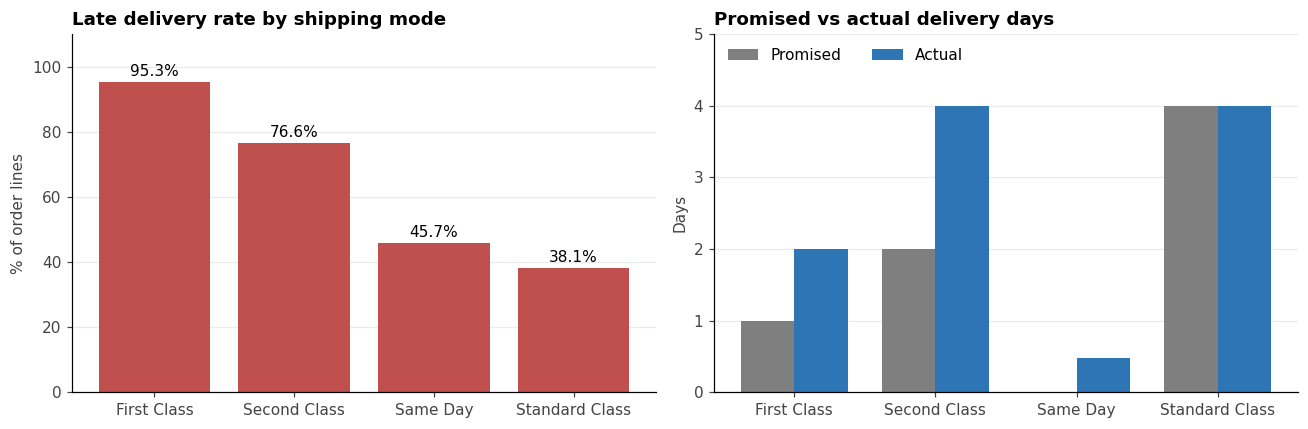

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(by_mode.index, by_mode["late_rate"] * 100, color=RED)
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=2)
axes[0].set_ylim(0, 110); axes[0].set_ylabel("% of order lines")
axes[0].set_title("Late delivery rate by shipping mode")

x, width = np.arange(len(by_mode)), 0.38
axes[1].bar(x - width / 2, by_mode["promised_days"], width, label="Promised", color=GREY)
axes[1].bar(x + width / 2, by_mode["actual_days"], width, label="Actual", color=BLUE)
axes[1].set_xticks(x); axes[1].set_xticklabels(by_mode.index)
axes[1].set_ylabel("Days"); axes[1].legend(frameon=False, loc="upper left", ncol=2)
axes[1].set_ylim(0, by_mode[["promised_days", "actual_days"]].to_numpy().max() * 1.25)
axes[1].set_title("Promised vs actual delivery days")
plt.tight_layout(); plt.show()

In [22]:
# How much of the lateness comes from each mode?
late_share = (df.groupby("Shipping Mode")
                .agg(order_lines=("late", "size"), late_lines=("late", "sum"))
                .assign(share_of_lines=lambda t: t["order_lines"] / t["order_lines"].sum(),
                        share_of_late_lines=lambda t: t["late_lines"] / t["late_lines"].sum())
                .sort_values("share_of_late_lines", ascending=False))

premium = late_share.loc[["First Class", "Second Class"]]
print(f"First + Second Class: {premium['share_of_lines'].sum():.1%} of order lines "
      f"but {premium['share_of_late_lines'].sum():.1%} of late lines\n")
pretty(late_share, order_lines="{:,.0f}", late_lines="{:,.0f}",
       share_of_lines="{:.1%}", share_of_late_lines="{:.1%}")

First + Second Class: 34.9% of order lines but 54.1% of late lines



,order_lines,late_lines,share_of_lines,share_of_late_lines
Shipping Mode,,,,
Standard Class,"107,752","41,023",59.7%,41.4%
Second Class,"35,216","26,987",19.5%,27.3%
First Class,"27,814","26,513",15.4%,26.8%
Same Day,"9,737","4,454",5.4%,4.5%


**What I found**

- **54.8% of order lines arrive late.** 23.0% arrive early, 17.8% on time and 4.3% are cancelled.
- Shipping mode explains the lateness: First Class 95.3%, Second Class 76.6%, Same Day 45.7% and Standard Class 38.1%.
- **First Class** is promised in 1 day but takes 2 on average, so it's late by a consistent 1 day.
- **Second Class** is promised in 2 days but takes 4.0, about the same as Standard Class (4.0 days). Customers on the faster tier get the slower tier's delivery time.
- **Standard Class** runs close to its 4-day promise (average delay of about zero), so its 38% late rate is early and late orders around the promise.
- First and Second Class are about **35% of order lines but about 54% of late lines**.

### 4.2 By market and region

In [23]:
by_market = (df.groupby("Market")
               .agg(order_lines=("late", "size"), late_rate=("late", "mean"), avg_delay_days=("delay_days", "mean"))
               .sort_values("late_rate", ascending=False))
pretty(by_market, order_lines="{:,.0f}", late_rate="{:.1%}", avg_delay_days="{:+.2f}")

,order_lines,late_rate,avg_delay_days
Market,,,
Europe,"50,252",55.2%,+0.57
Pacific Asia,"41,260",55.0%,+0.57
USCA,"25,799",54.8%,+0.57
Africa,"11,614",54.6%,+0.56
LATAM,"51,594",54.4%,+0.56


In [24]:
by_region = (df.groupby("Order Region")
               .agg(order_lines=("late", "size"), late_rate=("late", "mean"))
               .sort_values("late_rate", ascending=False))
pretty(by_region.head(10), order_lines="{:,.0f}", late_rate="{:.1%}")

,order_lines,late_rate
Order Region,,
Central Africa,"1,677",58.0%
South Asia,"7,731",56.3%
East Africa,"1,852",55.9%
Western Europe,"27,109",55.8%
South of USA,"4,045",55.8%
Eastern Europe,"3,920",55.7%
East of USA,"6,915",55.7%
Southeast Asia,"9,539",55.5%
Central Asia,553,55.3%


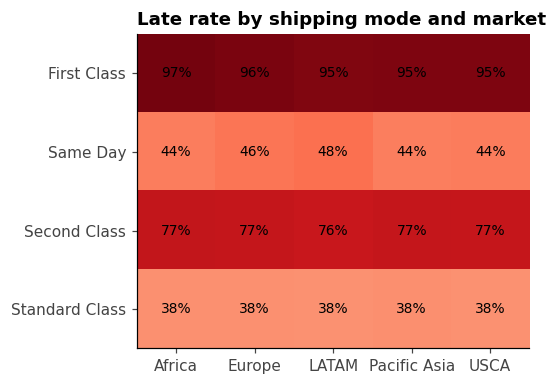

In [25]:
# Does the pattern hold in every market? Late rate by shipping mode and market
heat = df.pivot_table(index="Shipping Mode", columns="Market", values="late", aggfunc="mean").mul(100)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(heat, cmap="Reds", vmin=0, vmax=100)
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iloc[i, j]:.0f}%", ha="center", va="center", fontsize=9)
ax.grid(False); ax.set_title("Late rate by shipping mode and market")
plt.tight_layout(); plt.show()

**What I found**

- Markets barely differ: late rates run from 54.4% (LATAM) to 55.2% (Europe), against 54.8% overall.
- Regions vary a little more, but the highest, Central Africa (58.0%), has only 1,677 order lines, so I wouldn't read much into it.
- Within each shipping mode the rate is nearly the same in every market (Standard Class is 38% everywhere), so **geography isn't a driver**. Improvement effort belongs on promise-setting and fulfilment, not regional logistics.

## 5. Profitability

How often do order lines lose money, how much, and where?

In [26]:
# Profit structure: what the profitable lines earn versus what the loss-making lines give back
gross_profit = df["Order Profit Per Order"].clip(lower=0).sum()
losses = -df["loss_amount"].sum()

structure = pd.Series({
    "Profit on profitable lines": f"{gross_profit:,.0f}",
    "Losses on loss-making lines": f"-{losses:,.0f}",
    "Net profit": f"{gross_profit - losses:,.0f}",
    "Losses as a share of gross profit": f"{losses / gross_profit:.1%}",
    "Loss-making lines": f"{df['loss'].mean():.1%}",
}, name="Value").to_frame()
structure

,Value
Profit on profitable lines,"7,850,450"
Losses on loss-making lines,"-3,883,547"
Net profit,"3,966,903"
Losses as a share of gross profit,49.5%
Loss-making lines,18.7%


### 5.1 Discounts

In [27]:
df["discount_band"] = pd.cut(df["Order Item Discount Rate"], [-0.001, 0.05, 0.10, 0.15, 0.20, 1.0],
                             labels=["0-5%", "5-10%", "10-15%", "15-20%", "20%+"])
by_discount = (df.groupby("discount_band", observed=True)
                 .agg(order_lines=("loss", "size"), loss_rate=("loss", "mean"), avg_profit=("Order Profit Per Order", "mean")))
pretty(by_discount, order_lines="{:,.0f}", loss_rate="{:.1%}", avg_profit="{:.1f}")

,order_lines,loss_rate,avg_profit
discount_band,,,
0-5%,"50,142",18.6%,23.9
5-10%,"40,116",18.4%,23.5
10-15%,"30,087",18.8%,21.5
15-20%,"40,116",18.9%,20.1
20%+,"20,058",19.0%,18.4


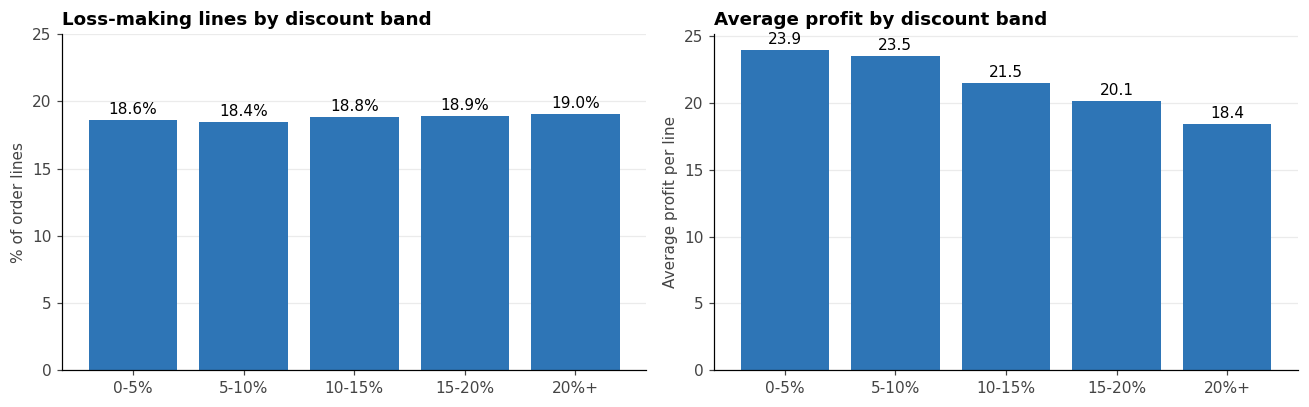

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(by_discount.index, by_discount["loss_rate"] * 100, color=BLUE)
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=2)
axes[0].set_ylim(0, 25); axes[0].set_ylabel("% of order lines")
axes[0].set_title("Loss-making lines by discount band")

axes[1].bar(by_discount.index, by_discount["avg_profit"], color=BLUE)
axes[1].bar_label(axes[1].containers[0], fmt="%.1f", padding=2)
axes[1].set_ylabel("Average profit per line")
axes[1].set_title("Average profit by discount band")
plt.tight_layout(); plt.show()

### 5.2 Categories and products

In [29]:
# Categories with 2,000+ lines, ranked by dollar losses (small categories are too noisy to compare)
category_loss = (df.groupby("Category Name")
                   .agg(order_lines=("loss", "size"), loss_rate=("loss", "mean"),
                        total_loss=("loss_amount", "sum"), net_profit=("Order Profit Per Order", "sum"))
                   .query("order_lines >= 2000")
                   .sort_values("total_loss"))
pretty(category_loss.head(10), order_lines="{:,.0f}", loss_rate="{:.1%}", total_loss="{:,.0f}", net_profit="{:,.0f}")

,order_lines,loss_rate,total_loss,net_profit
Category Name,,,,
Fishing,"17,325",18.5%,"-728,571","756,221"
Cleats,"24,551",18.7%,"-452,594","494,637"
Camping & Hiking,"13,729",18.9%,"-443,082","427,456"
Cardio Equipment,"12,487",18.7%,"-402,647","383,011"
Water Sports,"15,540",18.8%,"-334,570","325,147"
Women's Apparel,"21,035",18.6%,"-323,773","350,421"
Men's Footwear,"22,246",18.7%,"-309,270","311,903"
Indoor/Outdoor Games,"19,298",18.7%,"-298,637","318,451"
Shop By Sport,"10,984",19.6%,"-144,311","129,814"


In [30]:
# Products with 500+ lines, ranked by dollar losses
product_loss = (df.groupby("Product Name")
                  .agg(order_lines=("loss", "size"), loss_rate=("loss", "mean"),
                       total_loss=("loss_amount", "sum"), avg_price=("Product Price", "mean"))
                  .query("order_lines >= 500")
                  .sort_values("total_loss"))
pretty(product_loss.head(10), order_lines="{:,.0f}", loss_rate="{:.1%}", total_loss="{:,.0f}", avg_price="{:,.2f}")

,order_lines,loss_rate,total_loss,avg_price
Product Name,,,,
Field & Stream Sportsman 16 Gun Fire Safe,"17,325",18.5%,"-728,571",399.98
Perfect Fitness Perfect Rip Deck,"24,515",18.7%,"-450,978",59.99
Diamondback Women's Serene Classic Comfort Bi,"13,729",18.9%,"-443,082",299.98
Nike Men's Free 5.0+ Running Shoe,"12,169",18.7%,"-400,015",99.99
Pelican Sunstream 100 Kayak,"15,500",18.8%,"-332,804",199.99
Nike Men's Dri-FIT Victory Golf Polo,"21,035",18.6%,"-323,773",50.00
Nike Men's CJ Elite 2 TD Football Cleat,"22,246",18.7%,"-309,270",129.99
O'Brien Men's Neoprene Life Vest,"19,298",18.7%,"-298,637",49.98
Under Armour Girls' Toddler Spine Surge Runni,"10,617",19.6%,"-139,661",39.99


### 5.3 Is any segment different?

In [31]:
# Lowest and highest loss rate within each way of cutting the data
cuts = []
for label, col in [("Category (2,000+ lines)", "Category Name"), ("Discount band", "discount_band"),
                   ("Order status", "Order Status"), ("Shipping mode", "Shipping Mode"),
                   ("Customer segment", "Customer Segment"), ("Market", "Market")]:
    g = df.groupby(col, observed=True).agg(lines=("loss", "size"), loss_rate=("loss", "mean"))
    if col == "Category Name":
        g = g[g["lines"] >= 2000]
    cuts.append({"Cut": label,
                 "Lowest": f"{g['loss_rate'].idxmin()} ({g['loss_rate'].min():.1%})",
                 "Highest": f"{g['loss_rate'].idxmax()} ({g['loss_rate'].max():.1%})",
                 "Spread (pts)": round((g["loss_rate"].max() - g["loss_rate"].min()) * 100, 1)})
pd.DataFrame(cuts).set_index("Cut")

,Lowest,Highest,Spread (pts)
Cut,,,
"Category (2,000+ lines)",Electronics (17.8%),Shop By Sport (19.6%),1.8
Discount band,5-10% (18.4%),20%+ (19.0%),0.6
Order status,CLOSED (18.4%),ON_HOLD (19.8%),1.5
Shipping mode,First Class (18.3%),Standard Class (18.9%),0.5
Customer segment,Consumer (18.6%),Home Office (18.8%),0.2
Market,Africa (18.6%),Pacific Asia (18.9%),0.3


**What I found**

- **18.7% of order lines lose money.** Net profit is 3.97M on 36.78M of sales, a margin of about 10.8%.
- Those losses total 3.88M, which **offsets about 49%** of the 7.85M earned on profitable lines.
- Losses are **spread evenly**. The loss rate sits between roughly 18% and 20% in every cut I tried: category, product, discount band, order status, shipping mode, customer segment and market.
- Dollar losses simply follow volume. Fishing has the biggest loss (729K) but also the biggest profit in that table (756K), so it isn't a problem category.
- Discount depth doesn't change how often lines lose money (18.4% to 19.0%), but average profit per line falls from 23.9 to 18.4 (about 23%) between the lowest and highest discount bands.
- Products tell the same story: the top products each lose money on about 18% to 20% of their lines.

## 6. Demand and forecast

Before forecasting, I checked that the order series is stable. A structural change in the data would make any backtest unreliable.

### 6.1 Stability check

In [32]:
df["month"] = df[DATE].dt.to_period("M").dt.to_timestamp()
monthly = df.groupby("month").agg(order_lines=("Order Id", "size"),
                                  orders=("Order Id", "nunique"),
                                  sales=("Sales", "sum"),
                                  avg_line_sales=("Sales", "mean"))
monthly["lines_per_order"] = monthly["order_lines"] / monthly["orders"]

pretty(monthly.tail(8), order_lines="{:,.0f}", orders="{:,.0f}", sales="{:,.0f}",
       avg_line_sales="{:.1f}", lines_per_order="{:.2f}")

,order_lines,orders,sales,avg_line_sales,lines_per_order
month,,,,,
2017-06-01,"4,951","1,676","1,032,086",208.5,2.95
2017-07-01,"5,318","1,776","1,104,373",207.7,2.99
2017-08-01,"5,305","1,768","1,109,337",209.1,3.00
2017-09-01,"5,189","1,723","1,143,775",220.4,3.01
2017-10-01,"2,255","2,101","1,073,994",476.3,1.07
2017-11-01,"2,055","2,055","626,914",305.1,1.00
2017-12-01,"2,124","2,124","503,911",237.2,1.00
2018-01-01,"2,123","2,123","331,650",156.2,1.00


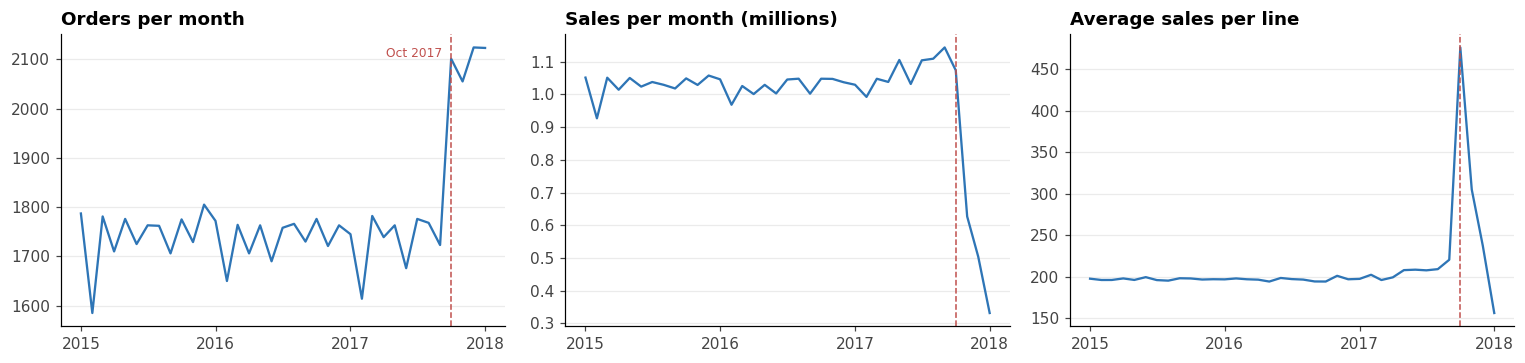

In [33]:
BREAK = pd.Timestamp("2017-10-01")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(monthly.index, monthly["orders"], color=BLUE);             axes[0].set_title("Orders per month")
axes[1].plot(monthly.index, monthly["sales"] / 1e6, color=BLUE);        axes[1].set_title("Sales per month (millions)")
axes[2].plot(monthly.index, monthly["avg_line_sales"], color=BLUE);     axes[2].set_title("Average sales per line")
for ax in axes:
    ax.axvline(BREAK, color=RED, linestyle="--", linewidth=1)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].annotate("Oct 2017", xy=(BREAK, monthly["orders"].max()), xytext=(-6, 0),
                 textcoords="offset points", ha="right", va="top", color=RED, fontsize=8)
plt.tight_layout(); plt.show()

In [34]:
# Compare the two periods either side of the break
df["period"] = np.where(df[DATE] < BREAK, "Jan 2015 - Sep 2017", "Oct 2017 - Jan 2018")
by_period = df.groupby("period").agg(
    order_lines=("late", "size"), late_rate=("late", "mean"), loss_rate=("loss", "mean"),
    avg_line_sales=("Sales", "mean"),
    lines_per_order=("Order Id", lambda s: len(s) / s.nunique()))
pretty(by_period, order_lines="{:,.0f}", late_rate="{:.1%}", loss_rate="{:.1%}",
       avg_line_sales="{:.1f}", lines_per_order="{:.2f}")

,order_lines,late_rate,loss_rate,avg_line_sales,lines_per_order
period,,,,,
Jan 2015 - Sep 2017,"171,962",54.8%,18.7%,199.2,3.00
Oct 2017 - Jan 2018,"8,557",55.0%,18.8%,296.4,1.02


**What I found**

- For almost three years monthly orders sit at roughly 1,600 to 1,800, then the data changes shape in **October 2017**.
- From then on every order has a single line (lines per order drop from about 3.0 to 1.0), the average line value spikes to 476 before falling to 156, and monthly sales fall about 71% between September 2017 and January 2018 (1.14M to 0.33M).
- That looks like a change in how the data was captured rather than a real change in demand, but the data can't confirm the cause.
- The delivery and profit findings aren't affected. Late rate (54.8% vs 55.0%) and loss rate (18.7% vs 18.8%) are the same on both sides, and the later period is only 4.7% of lines (8,557).
- So I trained and tested the forecast on **Jan 2015 to Sep 2017 only** (33 months).

### 6.2 Comparing forecasting models

In [35]:
stable = monthly.loc[:"2017-09-01"].copy()
print(f"Stable period: {stable.index.min():%b %Y} to {stable.index.max():%b %Y} ({len(stable)} months)")


def mape(actual, pred):
    """Mean absolute percentage error."""
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return float(np.mean(np.abs((actual - pred) / actual)) * 100)


def forecast_with(name, train, h):
    """Forecast the next `h` months from `train` using the named model."""
    if name == "Seasonal naive":                      # same month last year
        idx = pd.date_range(train.index[-1], periods=h + 1, freq="MS")[1:]
        return pd.Series([train.iloc[-12 + i] for i in range(h)], index=idx)
    if name == "ETS":
        return ExponentialSmoothing(train, trend="add", damped_trend=True,
                                    seasonal="add", seasonal_periods=12).fit().forecast(h)
    if name == "ARIMA(1,1,1)":
        return SARIMAX(train, order=(1, 1, 1)).fit(disp=False).forecast(h)
    if name == "SARIMA(1,1,1)(0,1,0,12)":
        return SARIMAX(train, order=(1, 1, 1), seasonal_order=(0, 1, 0, 12)).fit(disp=False).forecast(h)
    raise ValueError(name)

Stable period: Jan 2015 to Sep 2017 (33 months)


In [36]:
# Backtest: hold out the last 6 months, then repeat 3 months earlier
MODELS = ["Seasonal naive", "ETS", "ARIMA(1,1,1)", "SARIMA(1,1,1)(0,1,0,12)"]
HOLDOUT = 6
rows = []
for window, offset in [("Latest 6 months (Apr-Sep 2017)", 0), ("3 months earlier (Jan-Jun 2017)", 3)]:
    series = stable["orders"].astype(float)
    series = series.iloc[: len(series) - offset] if offset else series
    train, test = series.iloc[:-HOLDOUT], series.iloc[-HOLDOUT:]
    for name in MODELS:
        try:
            pred = forecast_with(name, train, HOLDOUT)
            rows.append({"window": window, "model": name, "MAPE %": round(mape(test.values, pred.values), 1)})
        except Exception as e:
            print(f"Skipped {name} for '{window}': {type(e).__name__}")

results = pd.DataFrame(rows).pivot(index="model", columns="window", values="MAPE %")
results

window,3 months earlier (Jan-Jun 2017),Latest 6 months (Apr-Sep 2017)
model,,
"ARIMA(1,1,1)",2.8,1.7
ETS,1.1,1.0
"SARIMA(1,1,1)(0,1,0,12)",1.5,0.9
Seasonal naive,1.3,0.7


**What I found**

- I tested four models on two six-month windows (Apr to Sep 2017, and Jan to Jun 2017).
- The three seasonal models all land at about **1% error** (0.7% to 1.5%), while the non-seasonal ARIMA is clearly worse (1.7% to 2.8%).
- Seasonal naive (same month last year) is as accurate as ETS and SARIMA, so I went with it. It's simple and easy to explain to a planner.
- Two short windows aren't much evidence, so I'd treat gaps of a few tenths of a percentage point as noise.

### 6.3 Forecast

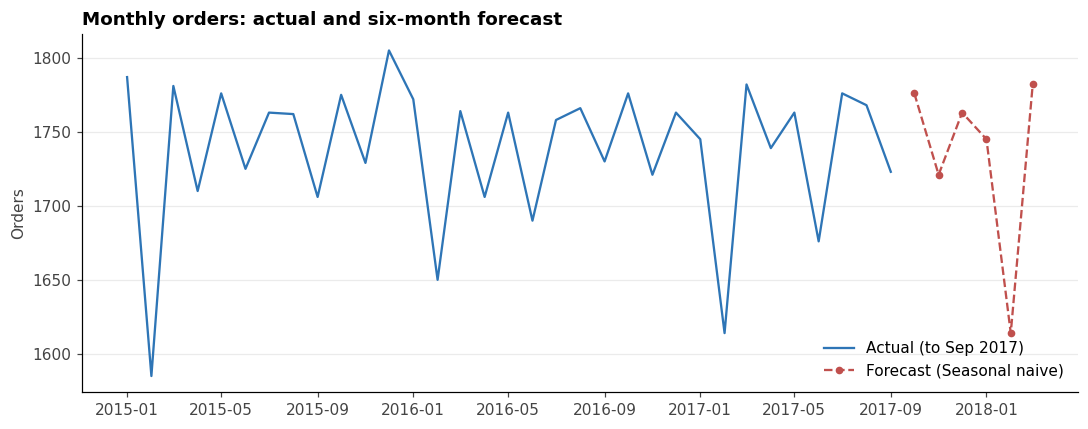

,forecast_orders
2017-10-01,1776.0
2017-11-01,1721.0
2017-12-01,1763.0
2018-01-01,1745.0
2018-02-01,1614.0
2018-03-01,1782.0


In [37]:
# Refit on the full stable period and project the next six months
BEST = "Seasonal naive"

history = stable["orders"].astype(float)
future = forecast_with(BEST, history, 6)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.index, history.values, color=BLUE, label="Actual (to Sep 2017)")
ax.plot(future.index, future.values, color=RED, linestyle="--", marker="o", markersize=4, label=f"Forecast ({BEST})")
ax.set_title("Monthly orders: actual and six-month forecast")
ax.set_ylabel("Orders"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

future.round(0).to_frame("forecast_orders")

**What I found**

- Expected demand for Oct 2017 to Mar 2018 averages **about 1,730 orders a month** (1,614 to 1,782), with February the low point.
- These are the same months where the data capture changes, so the forecast shows what demand would have looked like on the earlier pattern. Actual orders after September 2017 aren't comparable.

## 7. Findings, recommendations and limitations

### Findings

**Delivery**

- 54.8% of order lines arrive late, and shipping mode drives it (38.1% to 95.3%), not geography (54.4% to 55.2% across markets).
- First Class is promised in 1 day but takes 2. Second Class is promised in 2 days but takes about 4, the same as Standard Class.
- First and Second Class are about 35% of order lines but about 54% of late lines.

**Profitability**

- 18.7% of order lines lose money, and the losses offset about 49% of the profit on the profitable lines. Net margin is about 10.8%.
- Losses are spread evenly across categories, products, discount bands, order statuses, shipping modes, segments and markets. Extreme losses (below -1,000) are only 2.9% of the total.
- Deeper discounts don't make losses more frequent, but they cut average profit per line by about 23%.

**Demand**

- Order volume is steady and seasonal. A same-month-last-year baseline forecasts it to within about 1%, and expects about 1,730 orders a month for Oct 2017 to Mar 2018.

**Data**

- The data changes shape in October 2017 (one line per order from then on), and the later period is only 4.7% of lines.
- The catalogue is concentrated: 10 products make up 87.1% of order lines.

### Recommendations

*If this were our data, this is what I'd do:*

- **Fix the First Class promise.** Either reset it to 2 days to match what the network delivers, or fix the process behind it.
- **Review Second Class pricing.** It delivers in the same time as Standard, so it's worth checking whether the premium is justified.
- **Add a minimum-margin check at order-line level**, starting with the handful of products that carry most of the volume.
- **Exclude cancelled and suspected-fraud orders from revenue reporting**, and show order status as a filter on the dashboard.
- **Plan on the seasonal baseline**, and look into the data feed behind the October 2017 change before forecasting any further.

### Limitations

- **Several fields look rule-generated.** Each of the 18 discount levels is used on almost exactly the same number of lines, delays are fixed by shipping mode, lateness is identical across markets, and orders are flat across weekdays. The findings describe patterns in this dataset, not necessarily real-world customer or carrier behaviour.
- **The data changes in October 2017**, so the forecast uses 33 months, and it's backtested on only two short, overlapping windows.
- **The catalogue is thin.** A few products drive most of the volume, so conclusions about categories are really conclusions about individual products.
- **There's no cost data**, so profit can't be explained from the fields available.
- **Totals include cancelled, suspected-fraud and pending orders**, which a finance team would normally treat separately.

### Next step

The Power BI dashboard (delivery performance, profitability, forecast), built from the files exported below.

## 8. Exports for Power BI

Everything is saved to the `output/` folder in the project root. The cleaned order lines are large, so they're kept out of Git (see `.gitignore`).

In [38]:
# Cleaned order lines (helper columns, including the period flag, are kept; chart-only columns are dropped)
clean = df.drop(columns=["month", "discount_band"], errors="ignore")
clean.to_csv(OUTPUT_DIR / "clean_orders.csv", index=False)

# Summary tables
by_mode.to_csv(OUTPUT_DIR / "late_by_shipping_mode.csv")
by_market.to_csv(OUTPUT_DIR / "late_by_market.csv")
by_region.to_csv(OUTPUT_DIR / "late_by_order_region.csv")
category_loss.to_csv(OUTPUT_DIR / "loss_by_category.csv")
monthly.to_csv(OUTPUT_DIR / "monthly_actuals.csv")
future.rename("forecast_orders").to_csv(OUTPUT_DIR / "forecast_orders.csv")

print(f"Saved {len(list(OUTPUT_DIR.glob('*.csv')))} files to {OUTPUT_DIR}")

Saved 7 files to ..\output
